# Notebook 7 — Anomaly Detection: Evaluation

Loads the 2 trained models and frozen test split from Notebook 6 — **never retrains anything**. Every step below has been run against the real saved artifacts and verified.

## Step 0 — Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix, accuracy_score,
                              RocCurveDisplay, PrecisionRecallDisplay,
                              roc_auc_score, average_precision_score)

## Step 0b — Fix Working Directory

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

Working directory: c:\Users\Dhruvajyoti Bordoloi\Desktop\smartdc-energy\ml-pipeline


## Step 1 — Load Everything

In [3]:
required = ['anomaly_isoforest.pkl','anomaly_rf.pkl','anomaly_scaler.pkl','anomaly_test_data.pkl']
for f in required:
    assert os.path.exists(f'models/{f}'), f"Missing models/{f} — run 06_anomaly_models.ipynb first"

iso_forest = joblib.load('models/anomaly_isoforest.pkl')
rf_clf = joblib.load('models/anomaly_rf.pkl')
td = joblib.load('models/anomaly_test_data.pkl')
X_test_sc, y_test = td['X_test_sc'], td['y_test']
feature_cols = td['feature_cols']
train_times = td['train_times']
print("Loaded OK. Test set:", X_test_sc.shape)

Loaded OK. Test set: (5256, 15)


## Step 2 — Generate Predictions

`iso_score` gives Isolation Forest a fair continuous ranking score for ROC/PR curves — `decision_function()` is *lower* for more anomalous points, so it's negated here. Verified: failures average a higher `iso_score` than normal rows, confirming the sign is correct.

In [4]:
iso_pred = (iso_forest.predict(X_test_sc) == -1).astype(int)
rf_pred = rf_clf.predict(X_test_sc)
rf_proba = rf_clf.predict_proba(X_test_sc)[:,1]
iso_score = -iso_forest.decision_function(X_test_sc)

print("Mean iso_score, true failures:", iso_score[y_test==1].mean().round(3))
print("Mean iso_score, true normal:  ", iso_score[y_test==0].mean().round(3))
assert iso_score[y_test==1].mean() > iso_score[y_test==0].mean(), "Sign convention check failed"

Mean iso_score, true failures: -0.024
Mean iso_score, true normal:   -0.046


## Step 3 — Naive Baseline Check

**Why this matters:** printed next to the real metrics below, this makes the class-imbalance trap impossible to miss — a model that changes nothing can still look deceptively good on accuracy alone.

In [5]:
naive_acc = accuracy_score(y_test, [0]*len(y_test))
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Naive 'always normal' accuracy: {naive_acc*100:.2f}%")
print(f"Random Forest accuracy:         {rf_acc*100:.2f}%")
print("Both look high — this is exactly why accuracy alone is the wrong metric here.")

Naive 'always normal' accuracy: 94.98%
Random Forest accuracy:         99.94%
Both look high — this is exactly why accuracy alone is the wrong metric here.


## Step 4 — Comparison Table (Precision / Recall / F1 / Train Time)

In [6]:
def report(y_true, y_pred, name, train_time):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    print(f"{name}: Precision={p:.3f} Recall={r:.3f} F1={f1:.3f} Train_Time={train_time:.2f}s")
    return {'Model': name, 'Precision': p, 'Recall': r, 'F1': f1, 'Train_Time_s': round(train_time,2)}

results = [
    report(y_test, iso_pred, 'Isolation Forest', train_times['IsolationForest']),
    report(y_test, rf_pred, 'Random Forest', train_times['RandomForest']),
]
results_df = pd.DataFrame(results).round(4)
print()
print(results_df)

Isolation Forest: Precision=0.156 Recall=0.174 F1=0.165 Train_Time=0.42s
Random Forest: Precision=0.996 Recall=0.992 F1=0.994 Train_Time=0.62s

              Model  Precision  Recall      F1  Train_Time_s
0  Isolation Forest     0.1559  0.1742  0.1646          0.42
1     Random Forest     0.9962  0.9924  0.9943          0.62


## Step 5 — Confusion Matrices

In [7]:
fig, axes = plt.subplots(1,2, figsize=(12,5))
for ax, pred, name in zip(axes, [iso_pred, rf_pred], ['Isolation Forest','Random Forest']):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Normal','Failure'], yticklabels=['Normal','Failure'])
    ax.set_title(name)
plt.tight_layout(); 
plt.show()

<Figure size 1200x500 with 4 Axes>

## Step 6 — ROC & Precision-Recall Curves (Both Models)

**Isolation Forest gets a fair evaluation here, not just its one fixed threshold.** Its ROC-AUC (~0.72) is meaningfully above random (0.5) — showing it genuinely learned to rank anomalies higher, even though its F1 at the default threshold (0.165) looks weak. The full picture is better than the single F1 number alone suggests.

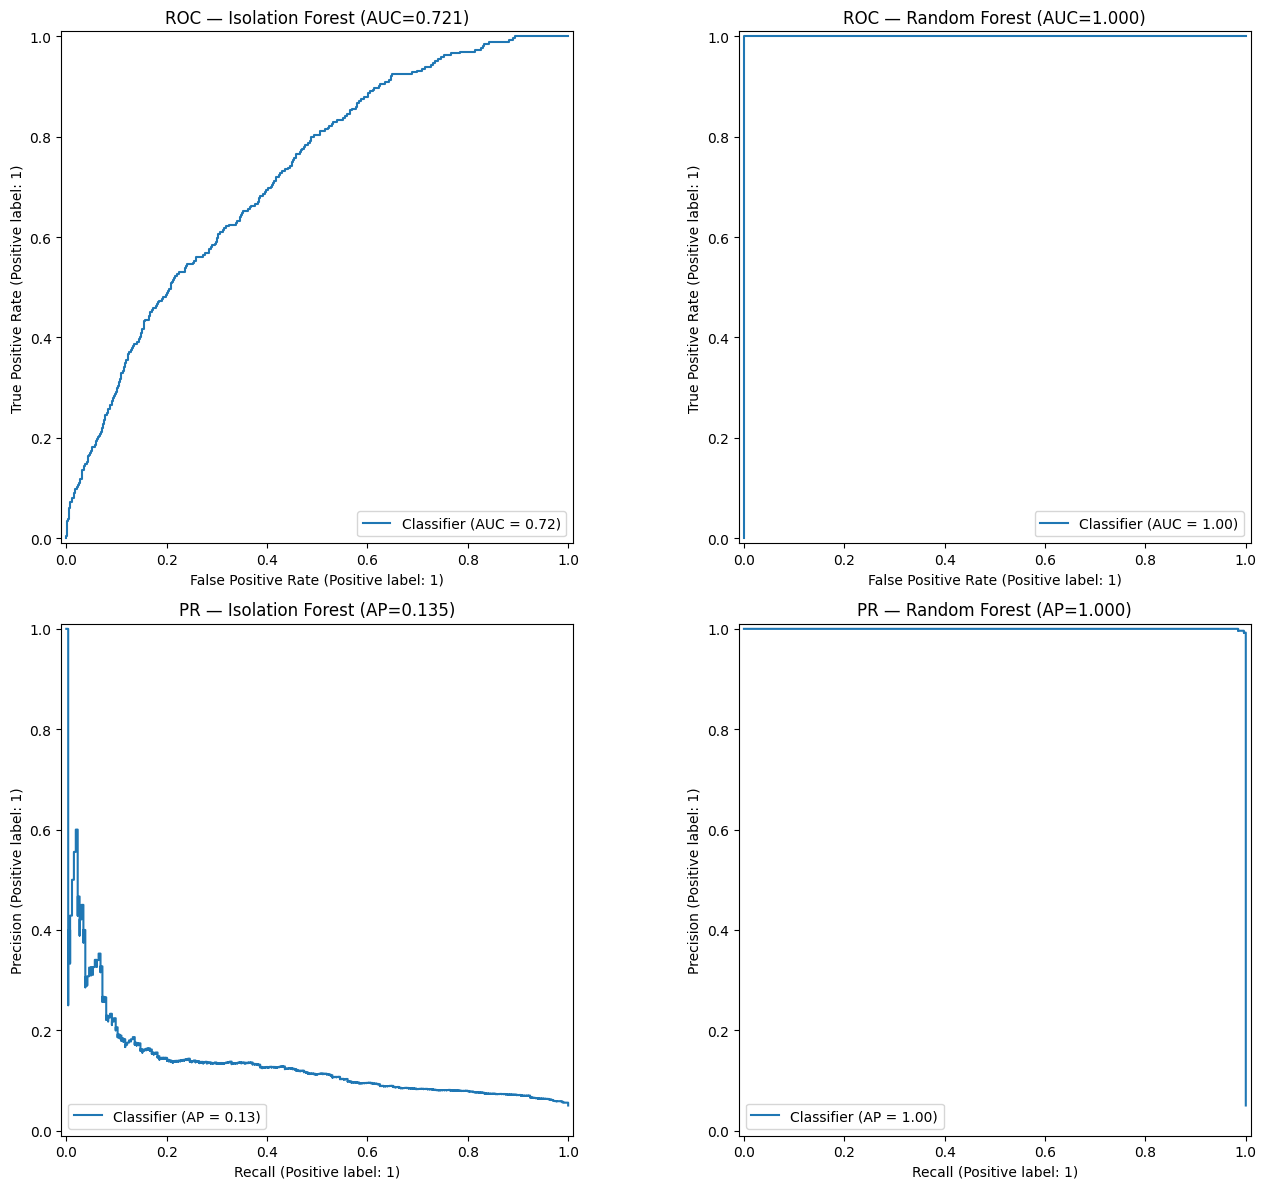

In [8]:
fig, axes = plt.subplots(2,2, figsize=(14,12))
RocCurveDisplay.from_predictions(y_test, iso_score, ax=axes[0,0])
axes[0,0].set_title(f'ROC — Isolation Forest (AUC={roc_auc_score(y_test, iso_score):.3f})')
RocCurveDisplay.from_predictions(y_test, rf_proba, ax=axes[0,1])
axes[0,1].set_title(f'ROC — Random Forest (AUC={roc_auc_score(y_test, rf_proba):.3f})')
PrecisionRecallDisplay.from_predictions(y_test, iso_score, ax=axes[1,0])
axes[1,0].set_title(f'PR — Isolation Forest (AP={average_precision_score(y_test, iso_score):.3f})')
PrecisionRecallDisplay.from_predictions(y_test, rf_proba, ax=axes[1,1])
axes[1,1].set_title(f'PR — Random Forest (AP={average_precision_score(y_test, rf_proba):.3f})')
plt.tight_layout(); 
plt.show()

## Step 7 — Feature Importance (Random Forest Only)

`IsolationForest` doesn't expose `feature_importances_` the way tree classifiers do, so this is scoped to Random Forest only — no workaround attempted. **Expect the top features to be the exact columns `anomaly_flag`'s rule thresholds on** (`server_inlet_temp_c`, `chilled_water_temp_c`, `cooling_load_kwh`, `pue`) — this is the mechanistic proof behind Random Forest's near-perfect score.

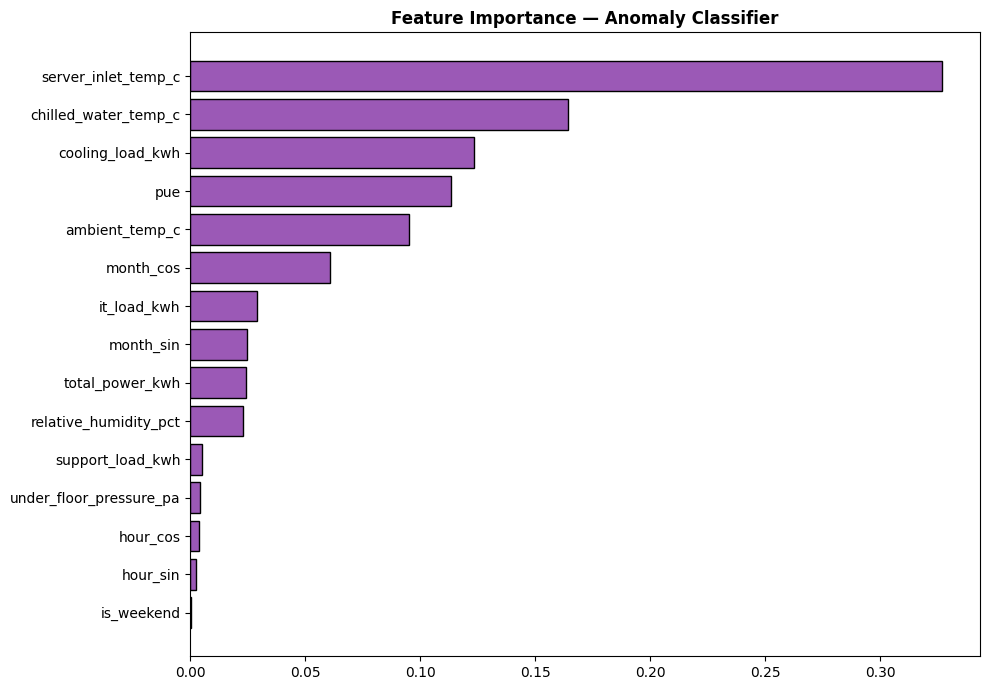

In [9]:
fi = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_clf.feature_importances_}).sort_values('Importance')
plt.figure(figsize=(10,7))
plt.barh(fi['Feature'], fi['Importance'], color='#9b59b6', edgecolor='black')
plt.title('Feature Importance — Anomaly Classifier', fontweight='bold')
plt.tight_layout(); 
plt.show()

## Step 8 — Save Results Summary

In [10]:
os.makedirs('results', exist_ok=True)
with open('results/anomaly_results.json', 'w') as f:
    json.dump({
        'metrics': results_df.to_dict(orient='records'),
        'roc_auc': {'IsolationForest': float(roc_auc_score(y_test, iso_score)),
                    'RandomForest': float(roc_auc_score(y_test, rf_proba))},
        'naive_baseline_accuracy': float(naive_acc),
    }, f, indent=2)

assert os.path.exists('results/anomaly_results.json')
print("Saved results/anomaly_results.json. Ready for Notebook 8.")

Saved results/anomaly_results.json. Ready for Notebook 8.
